# EDA Hortikultura Buah per Kecamatan — Kabupaten Kediri

Tujuan: memahami data **produksi buah** per kecamatan, lalu mengecek kesiapannya untuk **pemodelan prediksi produksi** (fitur Prediksi, Maps, dan Clustering di AgriDash).

Data sudah dibersihkan oleh tim, jadi notebook ini fokus ke: cek ulang cepat → EDA → cek kesiapan untuk model.

| File | Isi | Wajib? |
|---|---|---|
| `produksi_hortikultura_buah_per_kecamatan.csv` | produksi (kuintal) per kecamatan × komoditas | ya |
| `total_produksi_hortikultura_buah_kabupaten.csv` | total produksi tingkat kabupaten (untuk validasi) | tidak |
| `luas_lahan_per_kecamatan.csv` | luas sawah / bukan sawah per kecamatan (fitur pendukung) | tidak |

**Catatan:** untuk buah **tidak ada data luas panen**, jadi tidak ada produktivitas dan luas panen tidak bisa dipakai sebagai fitur seperti pada sayur.

**Cara pakai:** simpan notebook di folder `notebooks/`. File CSV boleh di folder mana saja di dalam `data/` (dicari otomatis).

## 1. Setup & Lokasi Data

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def cari_project_root(start_path=None):
    start = os.path.abspath(start_path or os.getcwd())
    current = start

    while True:
        if (
            os.path.isdir(os.path.join(current, "data"))
            and (
                os.path.isdir(os.path.join(current, "notebooks"))
                or os.path.isdir(os.path.join(current, ".git"))
            )
        ):
            return current

        parent = os.path.dirname(current)
        if parent == current:
            break
        current = parent

    return os.path.abspath(os.path.join(start, ".."))


PROJECT_ROOT = cari_project_root()
DATA_DIR = os.path.join(PROJECT_ROOT, "data")

# folder tempat file hasil cleaning (kalau beda, tidak masalah: file dicari otomatis di seluruh data/)
FOLDER_HORTI = os.path.join(DATA_DIR, "clean", "hortikultura")
# hasil olahan notebook ini
OUT_HORTI = os.path.join(DATA_DIR, "processed", "hortikultura")
os.makedirs(OUT_HORTI, exist_ok=True)


def cari_file(nama_file, folder_utama):
    langsung = os.path.join(folder_utama, nama_file)
    if os.path.isfile(langsung):
        return langsung
    ketemu = []
    for root, _, files in os.walk(DATA_DIR):
        if nama_file in files:
            ketemu.append(os.path.join(root, nama_file))
    if not ketemu:
        raise FileNotFoundError(f"'{nama_file}' tidak ditemukan di dalam {DATA_DIR}")
    ketemu.sort(key=lambda p: ("clean" not in p.lower(), p))      # utamakan folder 'clean'
    if len(ketemu) > 1:
        print(f"Ada {len(ketemu)} file bernama {nama_file}: {ketemu} -> dipakai yang pertama")
    return ketemu[0]


def coba_cari(nama_file, folder):
    try:
        return cari_file(nama_file, folder)
    except FileNotFoundError:
        return None


def kunci_nama(s):
    # samakan penulisan nama: huruf kecil, tanpa spasi ("Jeruk Lemon " -> "jeruklemon")
    return re.sub(r"\s+", "", str(s).lower())


def cocokkan_kab(nama_kab, kunci_kec):
    # nama di file kabupaten campur bahasa ("Alpukat/Avocado"). Dicocokkan ke nama kecamatan
    # yang menjadi awalan namanya; kalau ada beberapa yang cocok, ambil yang terpanjang.
    k = kunci_nama(nama_kab)
    cocok = [c for c in kunci_kec if k.startswith(c)]
    return max(cocok, key=len) if cocok else None


print("PROJECT ROOT :", PROJECT_ROOT)
print("DATA DIR     :", DATA_DIR)
print("OUTPUT       :", OUT_HORTI)

PROJECT ROOT : c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1
DATA DIR     : c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data
OUTPUT       : c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\processed\hortikultura


## 2. Muat Data

In [2]:
def baca_csv(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = df.columns.str.strip().str.lower()
    return df


F_PROD = cari_file("produksi_hortikultura_buah_per_kecamatan.csv", FOLDER_HORTI)
F_KAB = coba_cari("total_produksi_hortikultura_buah_kabupaten.csv", FOLDER_HORTI)
F_LAHAN = coba_cari("luas_lahan_per_kecamatan.csv", FOLDER_HORTI)

print("produksi buah (kecamatan) <-", F_PROD)
print("total buah (kabupaten)    <-", F_KAB or "TIDAK DITEMUKAN (validasi dilewati)")
print("luas lahan (kecamatan)    <-", F_LAHAN or "TIDAK DITEMUKAN (bagian lahan dilewati)", "\n")

prod_raw = baca_csv(F_PROD)
kab_raw = baca_csv(F_KAB) if F_KAB else None
lahan_raw = baca_csv(F_LAHAN) if F_LAHAN else None

# pemeriksaan kolom: kalau ada yang kurang, pesan error menampilkan kolom aslinya
wajib = ["kecamatan", "komoditas", "produksi_kuintal"]
if any(c not in prod_raw.columns for c in wajib):
    raise ValueError(f"Kolom tidak sesuai. Butuh {wajib}, yang ada: {prod_raw.columns.tolist()}")

print("produksi :", prod_raw.shape, "| kolom:", prod_raw.columns.tolist())
display(prod_raw.head())

produksi buah (kecamatan) <- c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\clean\hortikultura\produksi_hortikultura_buah_per_kecamatan.csv
total buah (kabupaten)    <- c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\clean\hortikultura\total_produksi_hortikultura_buah_kabupaten.csv
luas lahan (kecamatan)    <- c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\clean\tanaman_pangan\luas_lahan_per_kecamatan.csv 

produksi : (702, 3) | kolom: ['kecamatan', 'komoditas', 'produksi_kuintal']


,kecamatan,komoditas,produksi_kuintal
0,Mojo,Alpukat,"24,632.00"
1,Semen,Alpukat,"8,200.00"
2,Ngadiluwih,Alpukat,"3,604.00"
3,Kras,Alpukat,"3,540.00"
4,Ringinrejo,Alpukat,"12,272.00"


## 3. Cek Kualitas Data (cek ulang cepat)

In [3]:
print("baris:", len(prod_raw), "| kecamatan:", prod_raw["kecamatan"].nunique(), "| komoditas:", prod_raw["komoditas"].nunique())
print("nilai kosong:", int(prod_raw.isna().sum().sum()), "| duplikat (kecamatan+komoditas):", int(prod_raw.duplicated(["kecamatan", "komoditas"]).sum()))
print("Ada kolom tahun/periode?", any(c in prod_raw.columns for c in ["tahun", "periode", "bulan"]))
print("Ada kolom luas panen?   ", any("luas" in c for c in prod_raw.columns))
print(f"\nBaris produksi = 0     : {int((prod_raw['produksi_kuintal'] == 0).sum())} dari {len(prod_raw)}")
print(f"Baris produksi negatif : {int((prod_raw['produksi_kuintal'] < 0).sum())}")
print("Komoditas dengan nama ganda beda huruf besar/kecil:",
      [n for n, g in prod_raw.groupby(prod_raw["komoditas"].map(kunci_nama))["komoditas"].nunique().items() if g > 1])

baris: 702 | kecamatan: 26 | komoditas: 27
nilai kosong: 0 | duplikat (kecamatan+komoditas): 0
Ada kolom tahun/periode? False
Ada kolom luas panen?    False

Baris produksi = 0     : 369 dari 702
Baris produksi negatif : 0
Komoditas dengan nama ganda beda huruf besar/kecil: []


### 3.1 Validasi: jumlah semua kecamatan harus sama dengan angka kabupaten

In [4]:
if kab_raw is None:
    print("File kabupaten tidak ditemukan -> validasi dilewati.")
else:
    kunci_kec = sorted({kunci_nama(x) for x in prod_raw["komoditas"]})
    kab = kab_raw.copy()
    kab["k"] = kab["komoditas"].map(lambda x: cocokkan_kab(x, kunci_kec))
    tak_cocok = kab.loc[kab["k"].isna(), "komoditas"].tolist()
    jml_kec = prod_raw.assign(k=prod_raw["komoditas"].map(kunci_nama)).groupby("k")["produksi_kuintal"].sum().rename("jumlah_kecamatan")
    cek = kab.dropna(subset=["k"]).set_index("k")[["produksi_kuintal"]].rename(columns={"produksi_kuintal": "kabupaten"}).join(jml_kec)
    cek["selisih"] = cek["jumlah_kecamatan"] - cek["kabupaten"]
    print("Nama kabupaten yang tidak cocok dengan nama kecamatan:", tak_cocok)
    print("Selisih terbesar (kuintal):", f"{cek['selisih'].abs().max():.6f}")
    print("Satuan di file kabupaten  :", kab_raw["satuan"].unique().tolist() if "satuan" in kab_raw.columns else "-")

Nama kabupaten yang tidak cocok dengan nama kecamatan: []
Selisih terbesar (kuintal): 0.000000
Satuan di file kabupaten  : ['kw/qui']


**Temuan:**
- File rapi: tidak ada nilai kosong atau duplikat, 26 kecamatan × 27 komoditas = 702 baris.
- **Nilai 0 = tidak ada produksi/tidak tercatat**, bukan data hilang.
- **Produksi dalam kuintal** (1 kuintal = 100 kg).
- **Jumlah semua kecamatan sama persis dengan angka kabupaten** (selisih ≈ 0), jadi isi file konsisten.
- **Tidak ada kolom tahun/periode** dan **tidak ada data luas panen buah.**

## 4. Persiapan Data

Langkah: rapikan teks → produksi ke **ton** → tandai baris yang ada datanya (produksi > 0).

In [5]:
df = prod_raw.copy()
df["kecamatan"] = df["kecamatan"].astype(str).str.strip()
df["komoditas"] = df["komoditas"].astype(str).str.strip()
df["produksi_ton"] = df["produksi_kuintal"] / 10
df["ada_data"] = df["produksi_kuintal"] > 0
df = df[["kecamatan", "komoditas", "produksi_kuintal", "produksi_ton", "ada_data"]].sort_values(["komoditas", "kecamatan"]).reset_index(drop=True)

d = df[df["ada_data"]].copy()          # hanya baris yang ada datanya
print(f"Tabel : {len(df)} baris ({df['kecamatan'].nunique()} kecamatan x {df['komoditas'].nunique()} komoditas)")
print(f"Ada data: {len(d)} baris ({len(d)/len(df):.1%})")
df.head(8)

Tabel : 702 baris (26 kecamatan x 27 komoditas)
Ada data: 333 baris (47.4%)


,kecamatan,komoditas,produksi_kuintal,produksi_ton,ada_data
0,Badas,Alpukat,"1,026.00",102.60,True
1,Banyakan,Alpukat,"4,895.00",489.50,True
2,Gampengrejo,Alpukat,"1,019.00",101.90,True
3,Grogol,Alpukat,"17,300.00","1,730.00",True
4,Gurah,Alpukat,"1,343.00",134.30,True
5,Kandangan,Alpukat,"2,081.15",208.12,True
6,Kandat,Alpukat,"3,240.00",324.00,True
7,Kayenkidul,Alpukat,842.00,84.20,True


## 5. EDA

### 5.1 Ketersediaan data

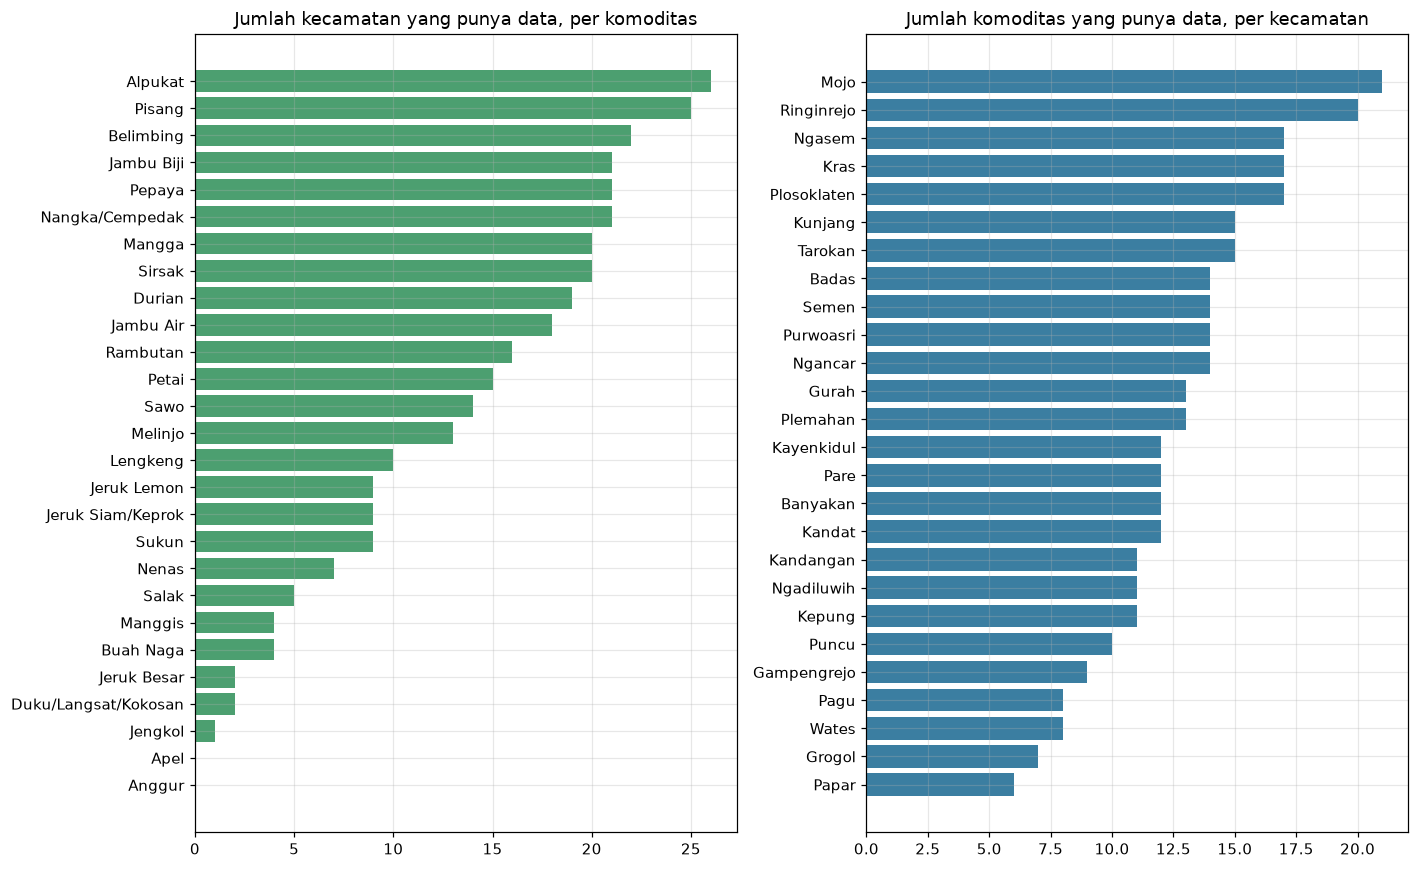

Komoditas TANPA data sama sekali: ['Anggur', 'Apel']
Kecamatan TANPA data sama sekali: []
Komoditas dengan data di <= 3 kecamatan: {'Jengkol': 1, 'Duku/Langsat/Kokosan': 2, 'Jeruk Besar': 2}


In [6]:
per_kom = df.groupby("komoditas")["ada_data"].sum().sort_values()
per_kec = df.groupby("kecamatan")["ada_data"].sum().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 8))
ax[0].barh(per_kom.index, per_kom.values, color="#4c9f70")
ax[0].set_title("Jumlah kecamatan yang punya data, per komoditas")
ax[1].barh(per_kec.index, per_kec.values, color="#3b7ea1")
ax[1].set_title("Jumlah komoditas yang punya data, per kecamatan")
plt.tight_layout(); plt.show()

print("Komoditas TANPA data sama sekali:", per_kom[per_kom == 0].index.tolist())
print("Kecamatan TANPA data sama sekali:", per_kec[per_kec == 0].index.tolist())
print("Komoditas dengan data di <= 3 kecamatan:", per_kom[(per_kom > 0) & (per_kom <= 3)].to_dict())

### 5.2 Statistik per komoditas

In [7]:
stat = (d.groupby("komoditas")
        .agg(n_kecamatan=("kecamatan", "nunique"),
             total_ton=("produksi_ton", "sum"),
             median_ton=("produksi_ton", "median"),
             maks_ton=("produksi_ton", "max"))
        .sort_values("total_ton", ascending=False))
stat["persen_total"] = stat["total_ton"] / stat["total_ton"].sum() * 100
stat

,n_kecamatan,total_ton,median_ton,maks_ton,persen_total
komoditas,,,,,
Nenas,7,"424,894.62","2,572.00","406,538.92",63.55
Mangga,20,"83,476.17",491.39,"29,000.00",12.49
Pisang,25,"62,222.28",950.00,"17,945.74",9.31
Alpukat,26,"22,817.09",339.00,"5,975.00",3.41
Durian,19,"20,230.65",68.88,"7,400.00",3.03
Jeruk Siam/Keprok,9,"11,226.75","1,125.50","3,217.80",1.68
Melinjo,13,"6,394.21",97.50,"3,628.58",0.96
Rambutan,16,"5,957.35",285.00,"1,579.35",0.89
Pepaya,21,"5,916.40",158.30,"1,938.70",0.88


### 5.3 Komoditas dominan

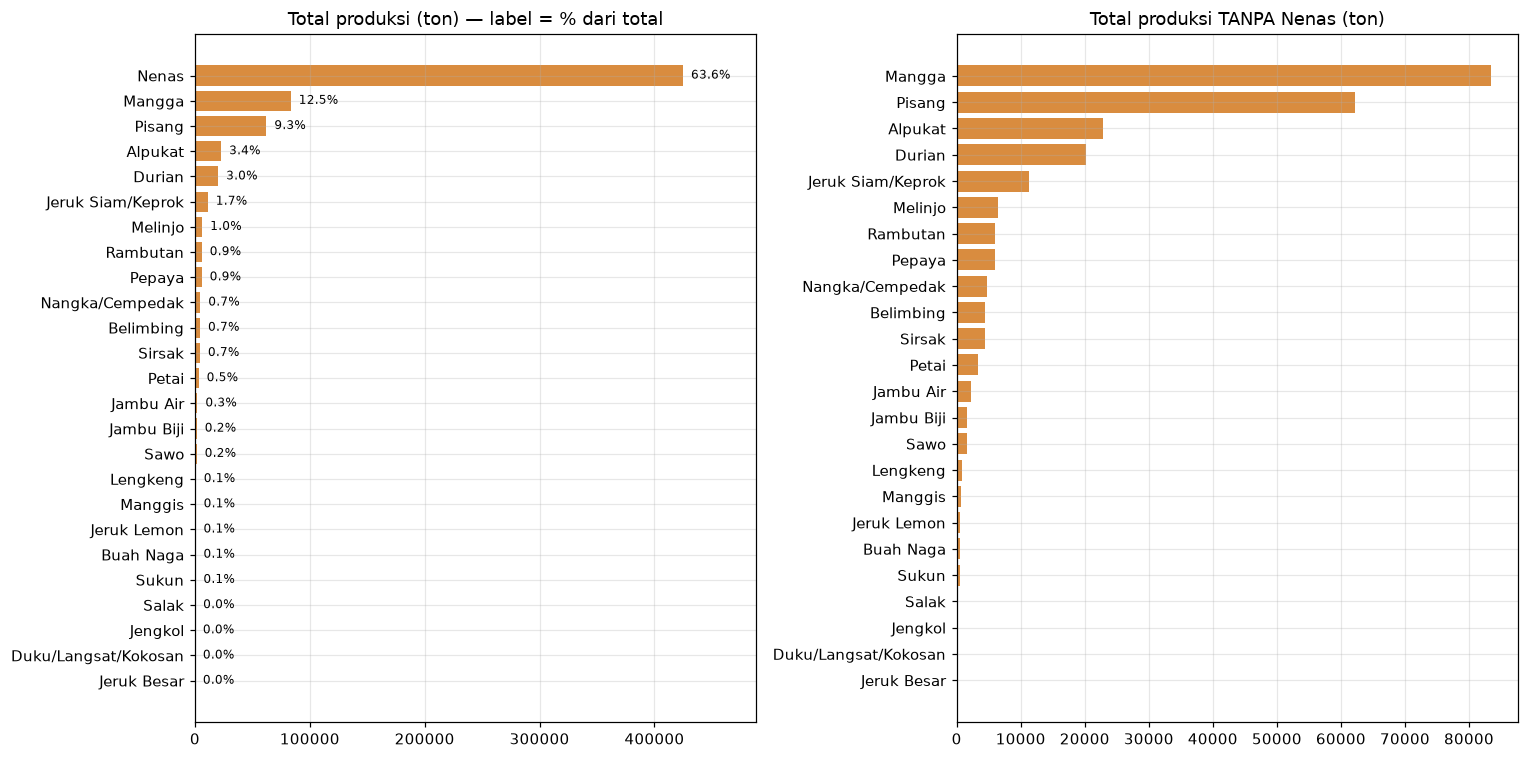

Porsi produksi terbesar: {'Nenas': 63.6, 'Mangga': 12.5, 'Pisang': 9.3, 'Alpukat': 3.4}


In [8]:
k = d.groupby("komoditas")["produksi_ton"].sum().sort_values()
persen = k / k.sum() * 100
k2 = k.drop("Nenas", errors="ignore")

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].barh(k.index, k.values, color="#d98c3f")
for y, (v, p) in enumerate(zip(k.values, persen.values)):
    ax[0].text(v, y, f"  {p:.1f}%", va="center", fontsize=8)
ax[0].set_xlim(0, k.max() * 1.15)
ax[0].set_title("Total produksi (ton) — label = % dari total")
ax[1].barh(k2.index, k2.values, color="#d98c3f")
ax[1].set_title("Total produksi TANPA Nenas (ton)")
plt.tight_layout(); plt.show()

print("Porsi produksi terbesar:", persen.sort_values(ascending=False).head(4).round(1).to_dict())

### 5.4 Nilai ekstrem

In [9]:
d["median_kom"] = d.groupby("komoditas")["produksi_ton"].transform("median")
d["n_kom"] = d.groupby("komoditas")["produksi_ton"].transform("count")
d["rasio_median"] = d["produksi_ton"] / d["median_kom"]

print("Nilai terbesar dibanding median komoditasnya (komoditas dengan >= 5 kecamatan):")
display(d[d["n_kom"] >= 5].nlargest(8, "rasio_median")[["kecamatan", "komoditas", "produksi_ton", "median_kom", "rasio_median"]])

pucuk = d.loc[d["produksi_ton"].idxmax()]
total_buah = d["produksi_ton"].sum()
total_komoditas = d.loc[d["komoditas"] == pucuk["komoditas"], "produksi_ton"].sum()
print(f"\nNilai tunggal terbesar: {pucuk['kecamatan']} - {pucuk['komoditas']} = {pucuk['produksi_ton']:,.0f} ton")
print(f"  = {pucuk['produksi_ton']/total_buah:.1%} dari SELURUH produksi buah Kabupaten")
print(f"  = {pucuk['produksi_ton']/total_komoditas:.1%} dari total {pucuk['komoditas']} Kabupaten")

Nilai terbesar dibanding median komoditasnya (komoditas dengan >= 5 kecamatan):


,kecamatan,komoditas,produksi_ton,median_kom,rasio_median
481,Ngancar,Nenas,"406,538.92","2,572.00",158.06
93,Pagu,Belimbing,"2,964.40",25.06,118.29
179,Semen,Durian,"7,400.00",68.88,107.43
365,Banyakan,Mangga,"29,000.00",491.39,59.02
388,Tarokan,Mangga,"26,168.19",491.39,53.25
305,Plosoklaten,Jeruk Lemon,310.00,5.90,52.54
167,Mojo,Durian,"3,574.50",68.88,51.89
164,Kepung,Durian,"3,295.00",68.88,47.84



Nilai tunggal terbesar: Ngancar - Nenas = 406,539 ton
  = 60.8% dari SELURUH produksi buah Kabupaten
  = 95.7% dari total Nenas Kabupaten


Satu nilai (Ngancar–Nenas) menyumbang lebih dari separuh seluruh produksi buah dan hampir semua produksi nenas. Ini bisa benar (sentra nenas), tapi **perlu dikonfirmasi ke sumber data**, karena satu titik ini akan mendominasi statistik dan model apa pun.

### 5.5 Kecamatan penghasil terbesar

,total_ton,n_komoditas,persen,persen_kumulatif,persen_tanpa_nilai_ekstrem
kecamatan,,,,,
Ngancar,"411,657.22",14,61.57,61.57,1.95
Banyakan,"33,742.70",12,5.05,66.62,12.88
Tarokan,"31,234.81",15,4.67,71.29,11.92
Kandangan,"23,147.10",11,3.46,74.75,8.83
Grogol,"22,754.25",7,3.40,78.16,8.68
Puncu,"17,645.40",10,2.64,80.80,6.73
Plosoklaten,"16,314.86",17,2.44,83.24,6.23
Kandat,"15,766.24",12,2.36,85.59,6.02
Mojo,"14,895.14",21,2.23,87.82,5.68


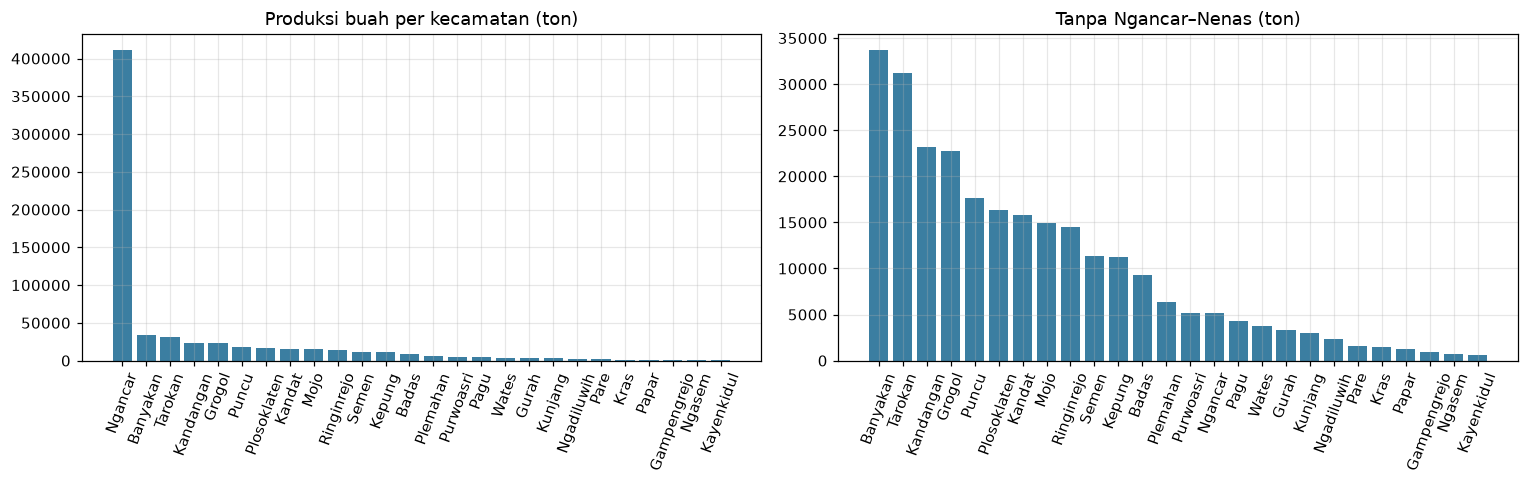

In [10]:
kc = (d.groupby("kecamatan")
      .agg(total_ton=("produksi_ton", "sum"), n_komoditas=("komoditas", "nunique"))
      .sort_values("total_ton", ascending=False))
kc["persen"] = kc["total_ton"] / kc["total_ton"].sum() * 100
kc["persen_kumulatif"] = kc["persen"].cumsum()

# pembanding: tanpa Ngancar-Nenas
tanpa = d[~((d["kecamatan"] == pucuk["kecamatan"]) & (d["komoditas"] == pucuk["komoditas"]))]
kc2 = tanpa.groupby("kecamatan")["produksi_ton"].sum().sort_values(ascending=False)
kc["persen_tanpa_nilai_ekstrem"] = (kc2 / kc2.sum() * 100).reindex(kc.index)
display(kc.head(10))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(kc.index, kc["total_ton"], color="#3b7ea1"); ax[0].tick_params(axis="x", rotation=70)
ax[0].set_title("Produksi buah per kecamatan (ton)")
ax[1].bar(kc2.index, kc2.values, color="#3b7ea1"); ax[1].tick_params(axis="x", rotation=70)
ax[1].set_title(f"Tanpa {pucuk['kecamatan']}–{pucuk['komoditas']} (ton)")
plt.tight_layout(); plt.show()

### 5.6 Heatmap produksi: kecamatan × komoditas

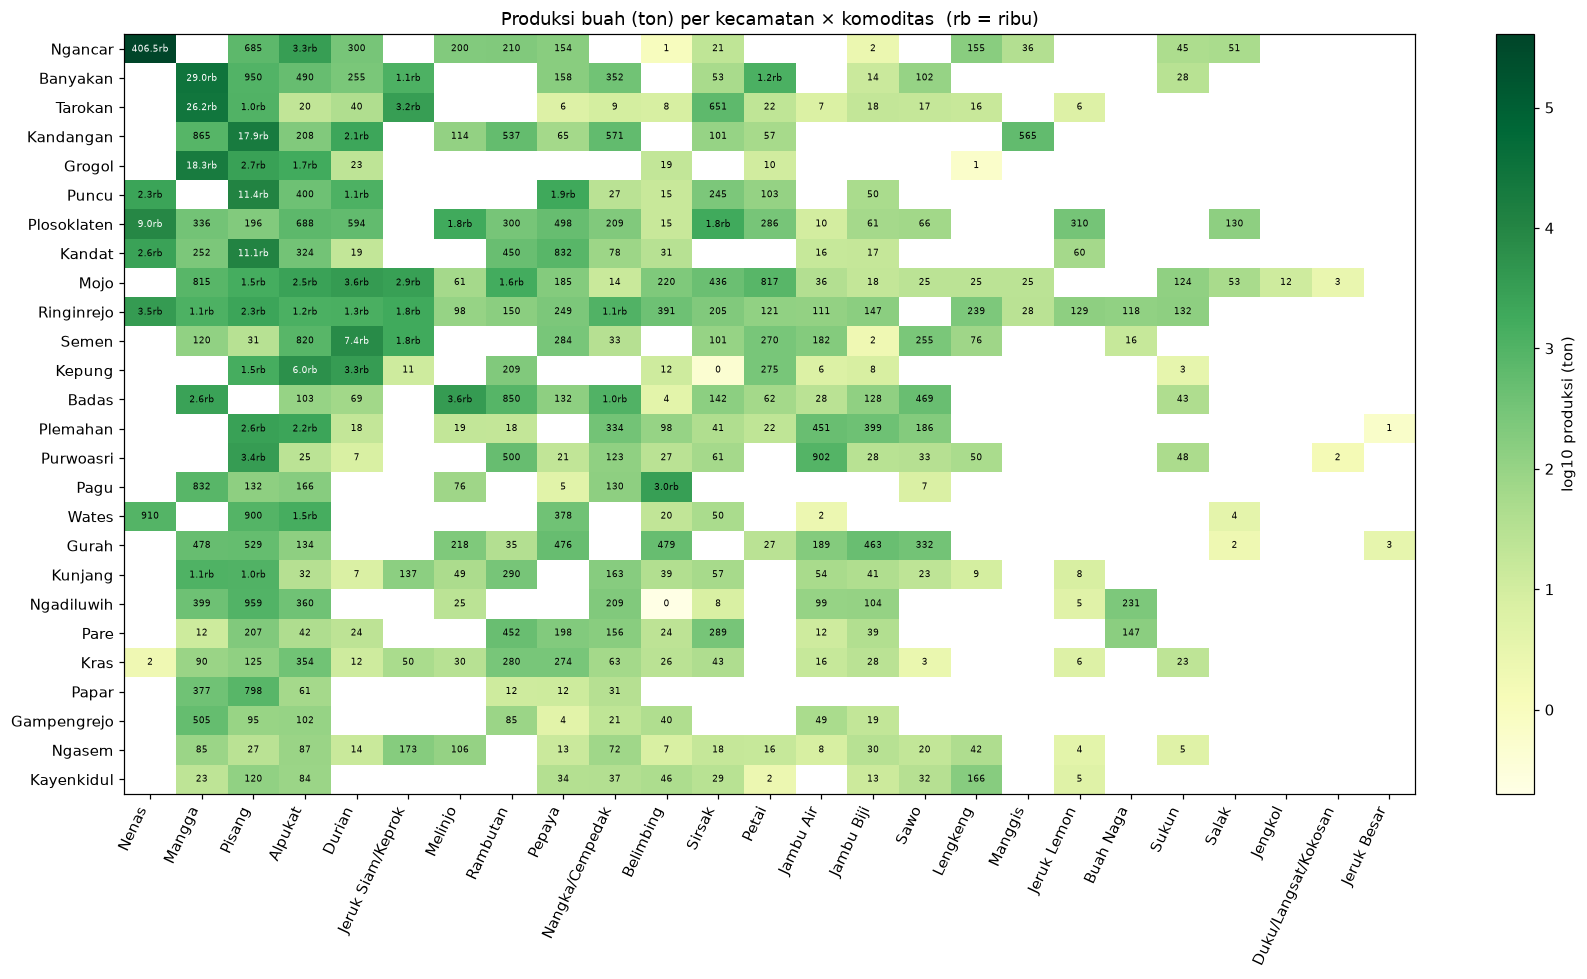

In [11]:
def ringkas(x):
    if pd.isna(x): return ""
    if x >= 1e3: return f"{x/1e3:.1f}rb"
    return f"{x:.0f}"

pvt = d.pivot_table(index="kecamatan", columns="komoditas", values="produksi_ton", aggfunc="sum")
pvt = pvt.loc[pvt.sum(axis=1).sort_values(ascending=False).index, pvt.sum().sort_values(ascending=False).index]
logv = np.log10(pvt)

fig, ax = plt.subplots(figsize=(16, 9))
im = ax.imshow(logv.values, cmap="YlGn", aspect="auto")
for i in range(pvt.shape[0]):
    for j in range(pvt.shape[1]):
        t = ringkas(pvt.iat[i, j])
        if t:
            ax.text(j, i, t, ha="center", va="center", fontsize=6,
                    color="white" if logv.iat[i, j] > 3.6 else "black")
ax.set_xticks(range(pvt.shape[1])); ax.set_xticklabels(pvt.columns, rotation=65, ha="right")
ax.set_yticks(range(pvt.shape[0])); ax.set_yticklabels(pvt.index)
ax.grid(False)
plt.colorbar(im, ax=ax, label="log10 produksi (ton)")
ax.set_title("Produksi buah (ton) per kecamatan × komoditas  (rb = ribu)")
plt.tight_layout(); plt.show()

### 5.7 Distribusi nilai

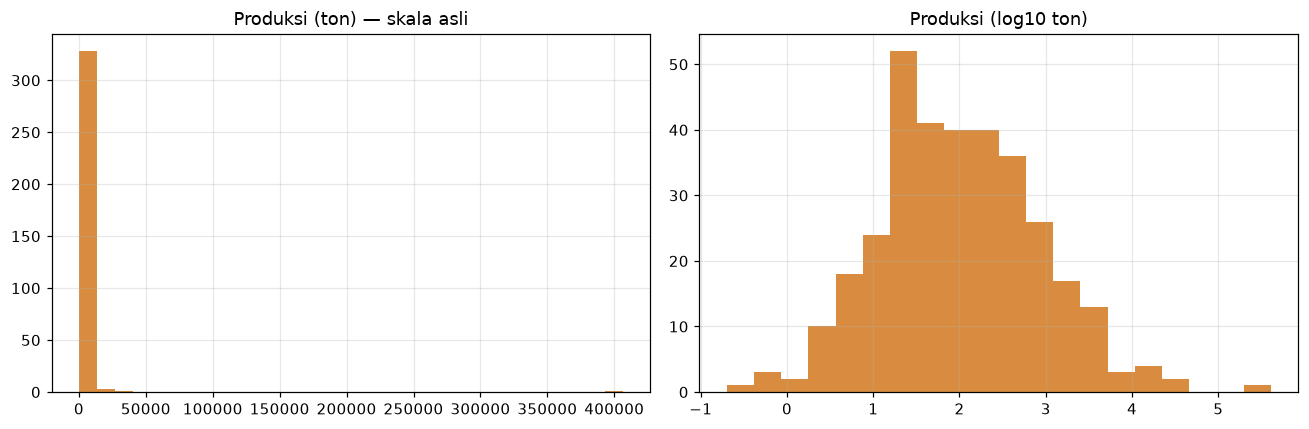

Skewness asli: 17.83 | setelah log: 0.23


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(d["produksi_ton"], bins=30, color="#d98c3f"); ax[0].set_title("Produksi (ton) — skala asli")
ax[1].hist(np.log10(d["produksi_ton"]), bins=20, color="#d98c3f"); ax[1].set_title("Produksi (log10 ton)")
plt.tight_layout(); plt.show()
print("Skewness asli:", round(d["produksi_ton"].skew(), 2), "| setelah log:", round(np.log10(d["produksi_ton"]).skew(), 2))

### 5.8 Sebaran produksi per komoditas

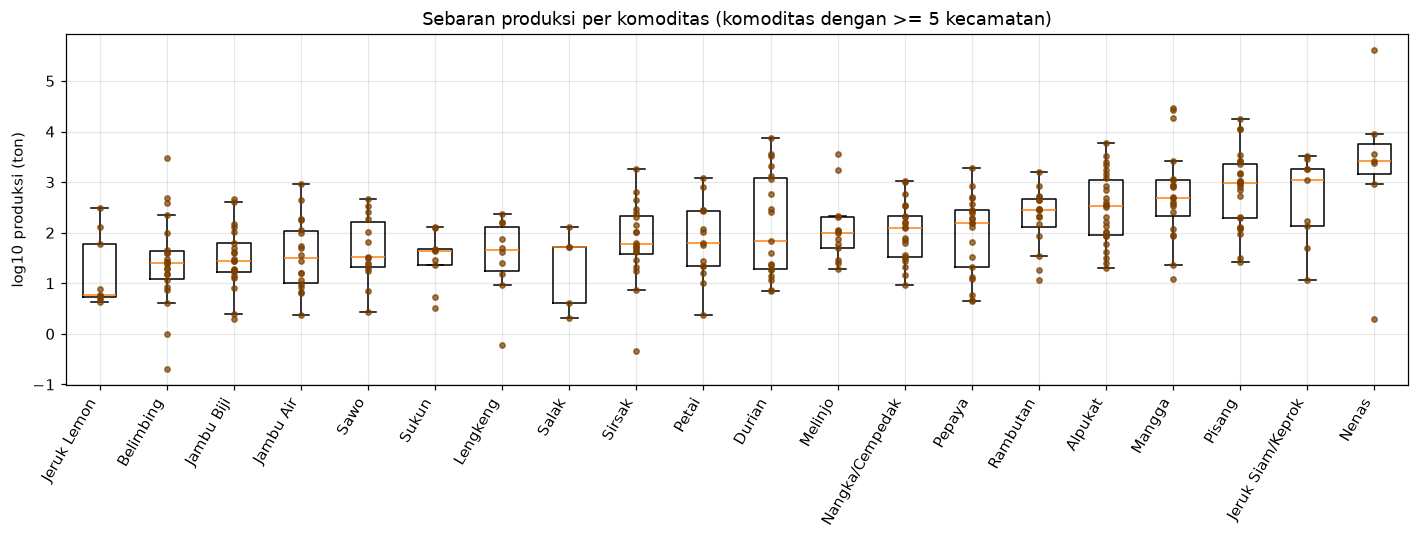

In [13]:
kom_ok = d.groupby("komoditas").size()
kom_ok = kom_ok[kom_ok >= 5].index
urut = d[d["komoditas"].isin(kom_ok)].groupby("komoditas")["produksi_ton"].median().sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(13, 5))
ax.boxplot([np.log10(d.loc[d["komoditas"] == n, "produksi_ton"].values) for n in urut], showfliers=False)
for i, n in enumerate(urut, start=1):
    v = np.log10(d.loc[d["komoditas"] == n, "produksi_ton"].values)
    ax.scatter(np.full(len(v), i), v, color="#7b3f00", s=12, alpha=.7, zorder=3)
ax.set_xticks(range(1, len(urut) + 1)); ax.set_xticklabels(urut, rotation=60, ha="right")
ax.set_ylabel("log10 produksi (ton)")
ax.set_title("Sebaran produksi per komoditas (komoditas dengan >= 5 kecamatan)")
plt.tight_layout(); plt.show()

## 6. Kesiapan untuk Pemodelan

Karena **tidak ada luas panen** untuk buah, fitur yang tersedia hanya **komoditas**, **kecamatan**, dan (kalau ada) **luas lahan kecamatan**. Dicek: seberapa jauh fitur-fitur itu bisa menebak produksi?

In [14]:
n_per = d.groupby("komoditas").size().sort_values(ascending=False)
print("Jumlah baris berdata:", len(d))
print("Komoditas dengan >= 15 baris:", n_per[n_per >= 15].index.tolist())
print("Komoditas dengan 5-14 baris :", n_per[(n_per >= 5) & (n_per < 15)].index.tolist())
print("Komoditas dengan < 5 baris  :", n_per[n_per < 5].index.tolist())

Jumlah baris berdata: 333
Komoditas dengan >= 15 baris: ['Alpukat', 'Pisang', 'Belimbing', 'Pepaya', 'Nangka/Cempedak', 'Jambu Biji', 'Sirsak', 'Mangga', 'Durian', 'Jambu Air', 'Rambutan', 'Petai']
Komoditas dengan 5-14 baris : ['Sawo', 'Melinjo', 'Lengkeng', 'Sukun', 'Jeruk Siam/Keprok', 'Jeruk Lemon', 'Nenas', 'Salak']
Komoditas dengan < 5 baris  : ['Manggis', 'Buah Naga', 'Duku/Langsat/Kokosan', 'Jeruk Besar', 'Jengkol']


In [15]:
# Hubungan produksi buah per kecamatan dengan luas lahan (kalau file lahan ada)
fitur_lahan = []
if lahan_raw is not None and {"kecamatan", "luas_sawah_ha", "luas_pertanian_bukan_sawah_ha"} <= set(lahan_raw.columns):
    lahan = lahan_raw[["kecamatan", "luas_sawah_ha", "luas_pertanian_bukan_sawah_ha"]].copy()
    lahan["kecamatan"] = lahan["kecamatan"].astype(str).str.strip()
    lahan["log_sawah"] = np.log10(lahan["luas_sawah_ha"] + 1)
    lahan["log_bukan_sawah"] = np.log10(lahan["luas_pertanian_bukan_sawah_ha"] + 1)
    fitur_lahan = ["log_sawah", "log_bukan_sawah"]

    gab = kc.join(lahan.set_index("kecamatan"), how="inner")
    print(f"Kecamatan yang cocok dengan data lahan: {len(gab)} dari {len(kc)}")
    kc_tanpa = kc2.rename("total_ton_tanpa_ekstrem").to_frame().join(lahan.set_index("kecamatan"), how="inner")
    for nama, tabel, kol in [("semua data", gab, "total_ton"), ("tanpa nilai ekstrem", kc_tanpa, "total_ton_tanpa_ekstrem")]:
        r1 = tabel[kol].corr(tabel["luas_pertanian_bukan_sawah_ha"], method="spearman")
        r2 = tabel[kol].corr(tabel["luas_sawah_ha"], method="spearman")
        print(f"Korelasi Spearman total produksi buah ({nama}): bukan sawah = {r1:.2f} | sawah = {r2:.2f}")
else:
    print("File lahan tidak ditemukan/kolom tidak sesuai -> bagian lahan dilewati.")

Kecamatan yang cocok dengan data lahan: 26 dari 26
Korelasi Spearman total produksi buah (semua data): bukan sawah = 0.65 | sawah = -0.15
Korelasi Spearman total produksi buah (tanpa nilai ekstrem): bukan sawah = 0.59 | sawah = -0.12


In [16]:
# Uji cepat (baseline) dengan validasi "tinggalkan satu kecamatan":
#   A = median produksi (skala log) komoditas itu di kecamatan LAIN
#   B = regresi linier di skala log: komoditas + luas lahan kecamatan (kalau ada)
d2 = d.copy()
d2["y"] = np.log10(d2["produksi_ton"])
if fitur_lahan:
    d2 = d2.merge(lahan[["kecamatan"] + fitur_lahan], on="kecamatan", how="left")

def desain(dd, kolom_kom, fitur):
    X = pd.get_dummies(dd["komoditas"]).reindex(columns=kolom_kom, fill_value=0).astype(float)
    for f in fitur:
        X[f] = dd[f].values
    return X.values

d2["pred_A"] = np.nan
d2["pred_B"] = np.nan
for kec in d2["kecamatan"].unique():
    latih = d2[d2["kecamatan"] != kec]
    idx = d2.index[d2["kecamatan"] == kec]
    uji = d2.loc[idx]
    med = latih.groupby("komoditas")["y"].median()
    d2.loc[idx, "pred_A"] = uji["komoditas"].map(med).values
    if fitur_lahan:
        kol_kom = sorted(latih["komoditas"].unique())
        beta = np.linalg.lstsq(desain(latih, kol_kom, fitur_lahan), latih["y"].values, rcond=None)[0]
        bisa = uji["komoditas"].isin(kol_kom).values
        pred = np.full(len(uji), np.nan)
        if bisa.any():
            pred[bisa] = desain(uji[bisa], kol_kom, fitur_lahan) @ beta
        d2.loc[idx, "pred_B"] = pred

def metrik(y, p):
    ok = ~(np.isnan(y) | np.isnan(p))
    y, p = y[ok], p[ok]
    r2 = 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    ape = np.abs(10 ** p - 10 ** y) / 10 ** y * 100
    return pd.Series({"baris diuji": int(ok.sum()), "R2 (log)": r2,
                      "meleset rata-rata (kali lipat)": 10 ** np.abs(y - p).mean(),
                      "median APE (%)": np.median(ape)})

baris = {"A: median komoditas": metrik(d2["y"].values, d2["pred_A"].values)}
if fitur_lahan:
    baris["B: komoditas + luas lahan"] = metrik(d2["y"].values, d2["pred_B"].values)
hasil = pd.DataFrame(baris).T
hasil["baris diuji"] = hasil["baris diuji"].astype(int)
hasil

,baris diuji,R2 (log),meleset rata-rata (kali lipat),median APE (%)
A: median komoditas,332,0.24,4.13,81.26
B: komoditas + luas lahan,332,0.23,4.29,85.57


**Cara membaca:** "meleset rata-rata (kali lipat)" = rata-rata tebakan meleset berapa kali lipat dari nilai sebenarnya (1,0 = tepat; 2,0 = rata-rata meleset 2× lebih besar/kecil). Model B hanya berguna kalau angkanya lebih baik daripada A. Model yang lebih rumit nanti harus mengalahkan patokan ini.

## 7. Kesimpulan

**Kualitas data**
- File konsisten: 26 kecamatan × 27 komoditas = 702 baris, tanpa nilai kosong atau duplikat. **Jumlah semua kecamatan sama persis dengan angka kabupaten.**
- **333 dari 702 baris (47,4%)** berisi data, lebih padat daripada sayur (27,7%). Hanya 2 komoditas tanpa data sama sekali (Anggur, Apel), dan semua kecamatan punya data.
- Tidak ada kolom tahun dan **tidak ada data luas panen buah**, jadi produktivitas tidak bisa dihitung.

**Isi data**
- **Nenas mendominasi (±64% total produksi)**, disusul Mangga (±12%), Pisang (±9%), dan Alpukat (±3%).
- **Satu nilai ekstrem: Ngancar–Nenas = ±406.539 ton**, yaitu ±61% dari seluruh produksi buah dan ±96% dari total nenas Kabupaten. Karena itu Ngancar tampak ±62% dari total, padahal tanpa nilai itu hanya ±2%. **Perlu dikonfirmasi ke sumber data.**
- Nilai ekstrem lain (puluhan sampai ratusan kali median komoditasnya): Pagu–Belimbing, Semen–Durian, Banyakan–Mangga, Tarokan–Mangga.
- Sebaran sangat miring (skewness ±18, setelah log ±0,2), jadi pakai **skala log**.
- Produksi buah per kecamatan cenderung lebih besar di kecamatan dengan lahan pertanian bukan sawah yang luas (korelasi Spearman ±0,65; ±0,59 tanpa nilai ekstrem). Ini di tingkat total kecamatan, dengan 26 titik saja.

**Kesiapan untuk model**
- Hanya 12 komoditas yang punya ≥15 baris, 8 komoditas 5–14 baris, dan 5 komoditas <5 baris.
- Uji cepat (validasi per kecamatan): menebak produksi dari **komoditas saja** hanya memberi **R² (log) ±0,24**, dengan tebakan rata-rata meleset **±4× lipat**. Menambah **luas lahan kecamatan tidak membantu** (R² ±0,23). Artinya fitur yang ada sekarang **belum cukup untuk memprediksi produksi buah dengan baik**.
- Tanpa kolom tahun, forecast time series juga belum bisa dibuat.

**Langkah berikutnya**
1. Tanyakan ke yang membersihkan data: (a) apakah ada data **luas panen / luas tanam / jumlah pohon** buah, (b) apakah ada versi **multi-tahun**, (c) apakah nilai **Ngancar–Nenas** sudah benar.
2. Selama fitur belum bertambah, data buah lebih cocok dipakai untuk **clustering/pemetaan potensi kecamatan** (fitur Pemetaan di AgriDash) daripada model prediksi produksi.
3. Kalau tetap mau model prediksi: pakai target `log(produksi)`, fokus ke komoditas dengan ≥15 baris, dan jadikan angka di bagian 6 sebagai patokan yang harus dikalahkan.

## 8. Simpan Data Hasil Olahan

In [17]:
df.to_csv(os.path.join(OUT_HORTI, "buah_kecamatan_gabungan.csv"), index=False)
d[["kecamatan", "komoditas", "produksi_kuintal", "produksi_ton", "ada_data"]].to_csv(
    os.path.join(OUT_HORTI, "buah_kecamatan_ada_data.csv"), index=False)

print("Tersimpan di:", OUT_HORTI)
for f in sorted(os.listdir(OUT_HORTI)):
    if f.endswith(".csv"):
        print(" -", f, f"({len(pd.read_csv(os.path.join(OUT_HORTI, f)))} baris)")

Tersimpan di: c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\processed\hortikultura
 - buah_kecamatan_ada_data.csv (333 baris)
 - buah_kecamatan_gabungan.csv (702 baris)
 - sayur_kecamatan_ada_data.csv (187 baris)
 - sayur_kecamatan_gabungan.csv (676 baris)
